# Linear and Logistic Regression

Linear and logistic regression are two supervised learning techniques used in machine learning to estimate the value or class of a case study given a set of characteristics and statistical patterns analyzed in past case studies. Linear regression aims to estimate a certain numerical value given a set of variables (a regression algorithm). Logistic regression, on the other hand, focuses on classifying a given case study (a classification algorithm).

## I – Linear Regression with Ecommerce Customers Dataset

An online clothing retailer intends to invest in improving one of its online sales platforms based on the income each provides. The available platforms are (1) a mobile application and (2) a web platform. A linear regression model was proposed to estimate the performance of each option and evaluate the best decision. To this end, the company provided a dataset containing the sales history of its customers and their respective information (e.g. email, address, time spent on each platform, total revenue acquired, etc.). This dataset is available at https://bit.ly/3mGDpu0.

After downloading the dataset, the intention is to:

## T1.
Load the dataset using the pandas.read_csv(…) function.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics
import time

In [2]:
ds_initial = pd.read_csv('datasets/EcommerceCustomers.csv')

## T2.
Apply methods for data exploration and visualization.

In [3]:
ds_initial.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 31.4 KB


In [4]:
ds_initial.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


<Axes: >

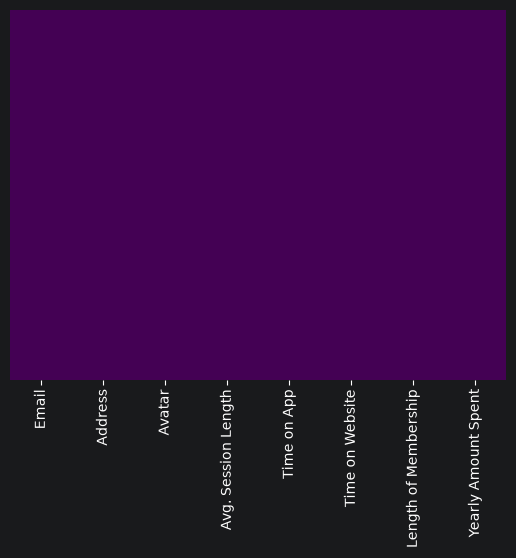

In [5]:
sns.heatmap(ds_initial.isnull(), yticklabels=False, cbar=False, cmap='viridis')

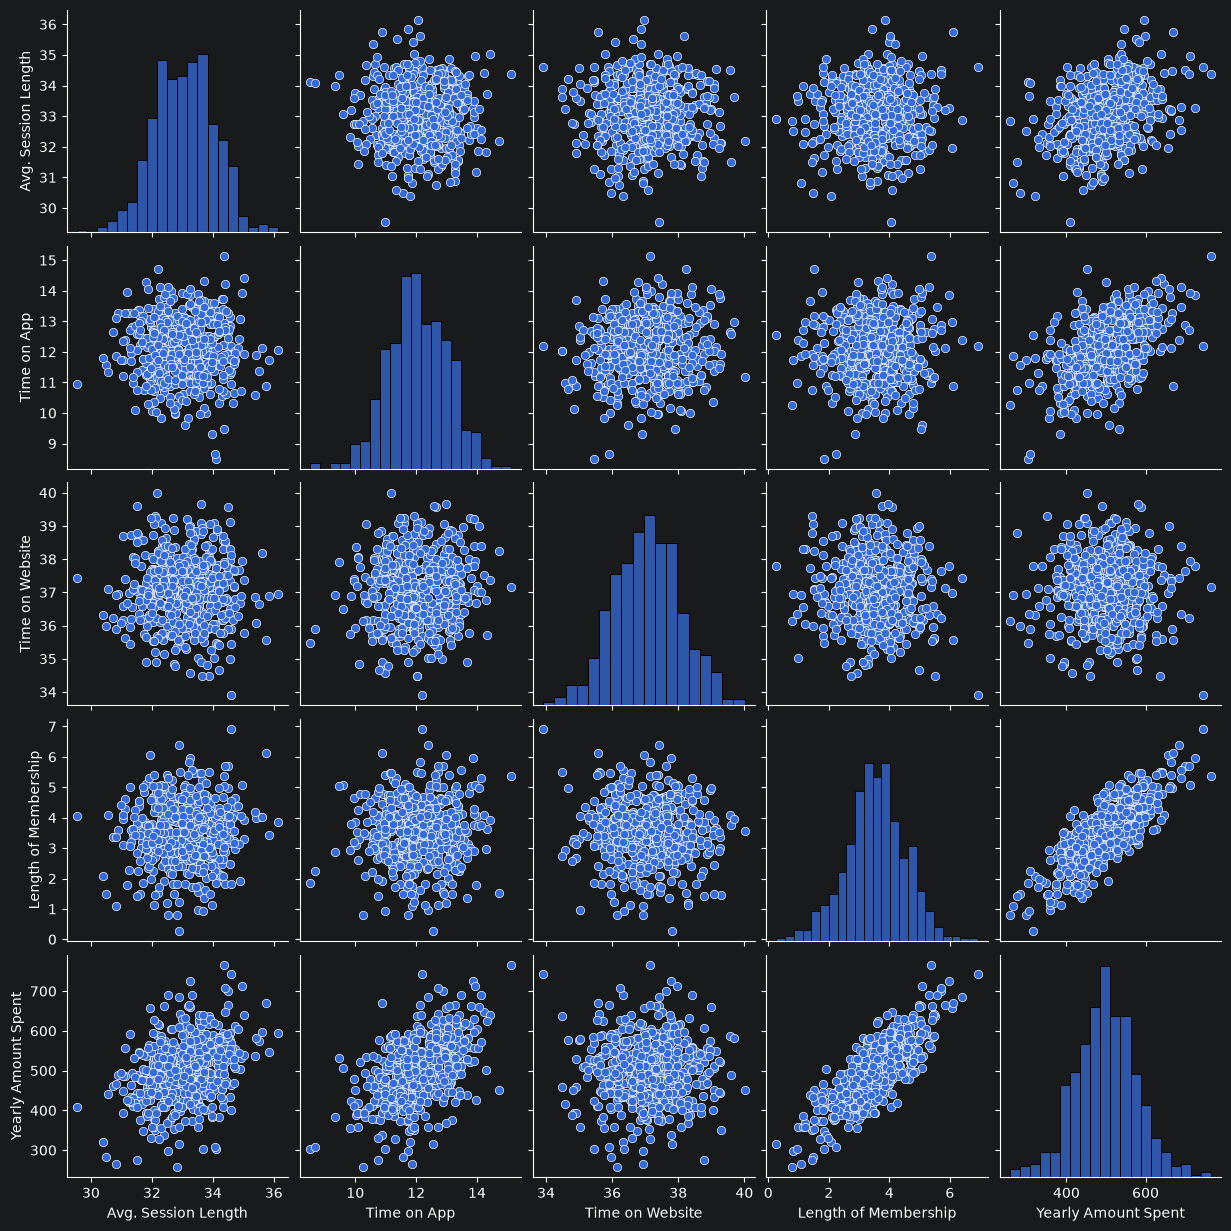

In [6]:
sns.pairplot(ds_initial)

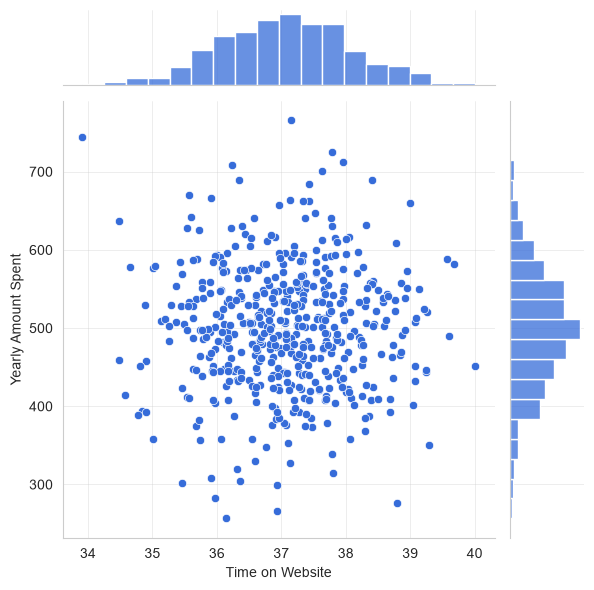

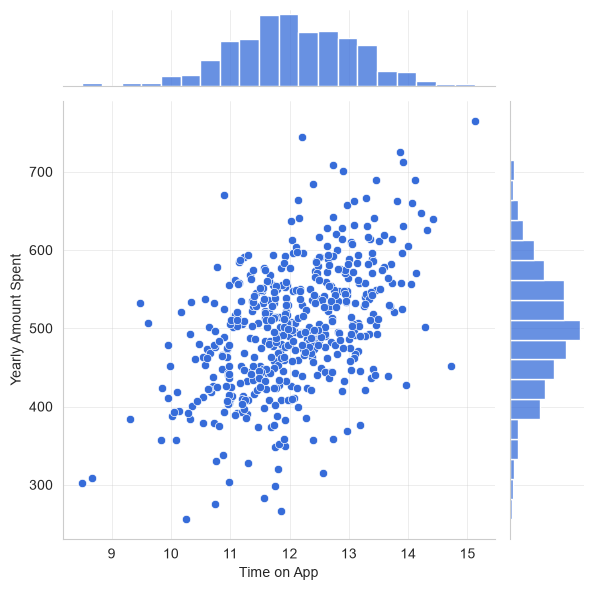

In [7]:
sns.set_style('whitegrid')
# Website vs App face ao gasto anual
sns.jointplot(x='Time on Website', y='Yearly Amount Spent', data=ds_initial)
sns.jointplot(x='Time on App', y='Yearly Amount Spent', data=ds_initial)
plt.show()

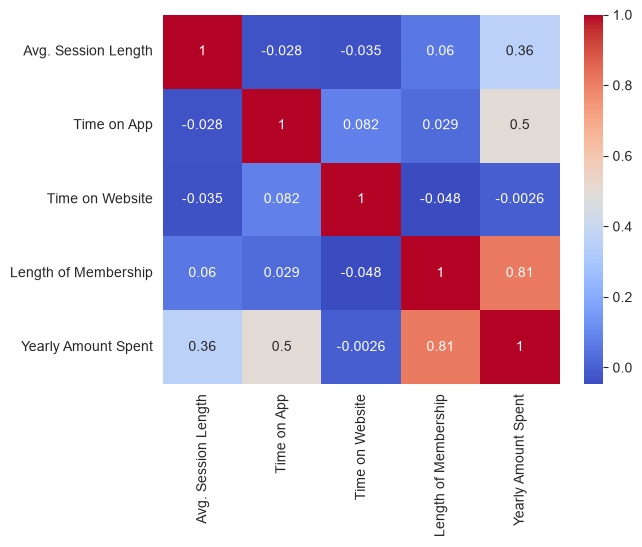

In [11]:
sns.heatmap(ds_initial.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

**Observações (500 clientes, sem valores em falta):**
- Correlação com *Yearly Amount Spent*: *Length of Membership* 0.81 (a mais forte), *Time on App* 0.50, *Avg. Session Length* 0.36 e *Time on Website* ≈ 0 (-0.003).
- As variáveis de entrada têm pouca correlação entre si (sem multicolinearidade relevante).

## T3
Define the set of input and output variables of the model (i.e., input = [“Avg. Session Length”, “Time on App”, “Time on Website”, “Length of Membership”]; output = [“Yearly Amount Spent”]).

In [12]:
X = ds_initial[['Avg. Session Length', 'Time on App', 'Time on Website', 'Length of Membership']]
y = ds_initial['Yearly Amount Spent']

In [15]:
X

,Avg. Session Length,Time on App,Time on Website,Length of Membership
0,34.497268,12.655651,39.577668,4.082621
1,31.926272,11.109461,37.268959,2.664034
2,33.000915,11.330278,37.110597,4.104543
3,34.305557,13.717514,36.721283,3.120179
4,33.330673,12.795189,37.536653,4.446308
...,...,...,...,...
495,33.237660,13.566160,36.417985,3.746573
496,34.702529,11.695736,37.190268,3.576526
497,32.646777,11.499409,38.332576,4.958264
498,33.322501,12.391423,36.840086,2.336485


In [16]:
y

0      587.951054
1      392.204933
2      487.547505
3      581.852344
4      599.406092
          ...    
495    573.847438
496    529.049004
497    551.620145
498    456.469510
499    497.778642
Name: Yearly Amount Spent, Length: 500, dtype: float64

## T4
Prepare and organize the set of case studies from the dataset into training and test data using the sklearn.model_selection.train_test_split(…) function with test_size = 0.3.

In [19]:
from sklearn.model_selection import train_test_split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(350, 4) (150, 4) (350,) (150,)


## T5
Train the linear regression model ( sklearn.linear_model.LinearRegression) using the training data.

In [23]:
from sklearn.linear_model import LinearRegression

In [24]:
lm = LinearRegression()
lm.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[25.98,38.59, 0.19,61.28]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Avg. Session Length','Time on App','Time on Website', 'Length of Membership']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1048
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


## T6.
Analyze the converged coefficients of the linear regression model and identify their significance in the context of the problem at hand.

In [27]:
features = ['Avg. Session Length', 'Time on App', 'Time on Website', 'Length of Membership']
print('Intercept:', lm.intercept_)
coeffs = pd.DataFrame(lm.coef_, index=features, columns=['Coeficiente'])
coeffs

Intercept: -1047.9327822502391


,Coeficiente
Avg. Session Length,25.981550
Time on App,38.590159
Time on Website,0.190405
Length of Membership,61.279097


**Interpretação** (mantendo as restantes variáveis constantes, o aumento de 1 unidade em cada variável associa-se a):
- *Avg. Session Length*: ~ +26 USD no gasto anual;
- *Time on App*: ~ +38 USD;
- *Time on Website*: ~ +0.19 USD (praticamente nulo);
- *Length of Membership*: ~ +61 USD (maior impacto).

(Valores obtidos com `random_state=101`; intercept ≈ -1047.93.)

**Conclusão para o negócio:** cada minuto adicional na **app** rende muito mais do que no **website**, cujo efeito é quase zero. Faz mais sentido investir na **app mobile**. Convém também notar que o *Length of Membership* é o fator mais forte, logo a retenção de clientes é muito valiosa. Como as variáveis estão em escalas diferentes, os coeficientes são comparáveis por unidade, mas não indicam diretamente "importância" relativa estatística.

## T7
Evaluate the Mean Absolute Error, Mean Squared Error and Root Mean Squared Error of the model developed for the 'Yearly Amount Spent' prediction (use the functions available in the sklearn.metrics library) and carry out the respective critical analysis.

In [28]:
predictions = lm.predict(X_test)

mae  = metrics.mean_absolute_error(y_test, predictions)
mse  = metrics.mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2   = metrics.r2_score(y_test, predictions)

print(f'MAE : {mae:.4f}')
print(f'MSE : {mse:.4f}')
print(f'RMSE: {rmse:.4f}')
print(f'R2  : {r2:.4f}')
print(f'RMSE / média do target: {rmse / y.mean():.2%}')

MAE : 7.2281
MSE : 79.8131
RMSE: 8.9338
R2  : 0.9890
RMSE / média do target: 1.79%


**Análise crítica:**
- Resultados: MAE = 7.23, MSE = 79.81, RMSE = 8.93, R² = 0.989.
- O gasto anual médio é ~499 USD, logo o RMSE corresponde a ~1.8% do valor médio: o modelo é muito preciso.
- O RMSE é ligeiramente superior ao MAE, o que indica alguns erros maiores pontuais (o MSE penaliza-os).
- O gráfico real vs. previsto é quase uma reta e os resíduos seguem uma distribuição aproximadamente normal e centrada em 0, o que valida o pressuposto de linearidade.
- Remover *Time on Website* (coeficiente ≈ 0) mantém praticamente o mesmo erro (RMSE ≈ 8.96 vs 8.93), confirmando que essa variável quase não contribui. Outras melhorias: Lasso/Ridge, validação cruzada ou mais dados (só há 500 clientes).

In [29]:
# (Opcional) Experiência: modelo sem 'Time on Website'
f2 = ['Avg. Session Length', 'Time on App', 'Length of Membership']
lm2 = LinearRegression().fit(X_train[f2], y_train)
p2 = lm2.predict(X_test[f2])
print('RMSE sem Website:', np.sqrt(metrics.mean_squared_error(y_test, p2)))

RMSE sem Website: 8.955191013818542
